# 03 · No budget constraint - Table 10, Figs. 2-4

Section 3.4: unlimited financial resources. Case 1 uses the original penalty factor
(12.5 kUSD/(y °C)); Case 2 a higher one (40 kUSD/(y °C)). The MINLP (Eqs. 1-55) is solved with
an NLP-based branch-and-bound with IPOPT node solves (`coolingnet.optimization.nlpbb`),
the same algorithmic family as the SBB/CONOPT pair used in the paper.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from coolingnet import paper_case
from coolingnet.optimization import SolverSettings
from coolingnet.reporting import figures as F
from coolingnet.reporting import paper_reference as REF
from coolingnet.reporting import tables as T
from coolingnet.workflow import PaperPipeline, PipelineConfig

RESULTS_DIR = Path("../results")
FORCE_RESOLVE = False

case = paper_case()
pipeline = PaperPipeline(case, PipelineConfig(results_dir=RESULTS_DIR, force=FORCE_RESOLVE, solver=SolverSettings(name="nlpbb", time_limit_s=900)))
sims = pipeline.run_simulations()
cases = pipeline.run_unlimited()
for name, s in cases.items():
    print(name, s.report["termination"], f"objective = {s.costs['total_cost'] / 1e3:.2f} kUSD/y", f"({s.report['time_s']:.0f} s)")

case1 optimal objective = 84.59 kUSD/y (5 s)
case2 optimal objective = 189.76 kUSD/y (5 s)


## Table 10 - optimization results, unlimited budget

In [2]:
table10 = T.table_unlimited_budget(sims["current"], cases)
display(table10)

,Current cooling water flow rate (kg/s),Optimal cooling water flow rate (kg/s) case1/case2,Valve head loss (m) case1/case2,Penalty (kUSD/y) case1/case2
Heat exchanger,,,,
E-101,11.92,13.56/13.72,0.00/0.00,0.00/0.00
E-102,28.85,30.52/29.83,1.13/0.26,19.67/66.44
E-103,35.57,40.29/41.44,0.00/0.00,18.65/57.10
E-104,15.53,19.96/22.78,0.00/0.00,13.22/27.01
E-105,3.23,3.88/3.94,0.84/1.11,0.00/0.00
Total,95.09,108.21/111.71,-,51.54/150.55


In [3]:
c1, c2 = cases["case1"].exchangers_df(), cases["case2"].exchangers_df()
computed = pd.DataFrame(
    {
        "Optimal flow Case 1 (kg/s)": c1["k_kg_s"],
        "Optimal flow Case 2 (kg/s)": c2["k_kg_s"],
        "Valve head loss Case 1 (m)": c1["valve_head_loss_m"],
        "Valve head loss Case 2 (m)": c2["valve_head_loss_m"],
        "Penalty Case 1 (kUSD/y)": c1["penalty_USD_y"] / 1e3,
        "Penalty Case 2 (kUSD/y)": c2["penalty_USD_y"] / 1e3,
    }
)
display(REF.compare(REF.TABLE10, computed).round(2))
display(T.table_costs(cases).round(2))

,Optimal flow Case 1 (kg/s) [paper],Optimal flow Case 1 (kg/s) [this work],Optimal flow Case 2 (kg/s) [paper],Optimal flow Case 2 (kg/s) [this work],Valve head loss Case 1 (m) [paper],Valve head loss Case 1 (m) [this work],Valve head loss Case 2 (m) [paper],Valve head loss Case 2 (m) [this work],Penalty Case 1 (kUSD/y) [paper],Penalty Case 1 (kUSD/y) [this work],Penalty Case 2 (kUSD/y) [paper],Penalty Case 2 (kUSD/y) [this work]
Heat exchanger,,,,,,,,,,,,
E-101,13.56,13.56,13.73,13.72,0.00,0.00,0.11,0.00,0.00,0.00,0.00,0.00
E-102,30.52,30.52,30.26,29.83,1.13,1.13,0.00,0.26,19.67,19.67,65.04,66.44
E-103,40.29,40.29,41.26,41.44,0.00,0.00,0.00,0.00,18.65,18.65,57.91,57.10
E-104,19.96,19.96,22.68,22.78,0.00,0.00,0.00,0.00,13.22,13.22,27.62,27.01
E-105,3.88,3.88,3.94,3.94,0.84,0.84,1.06,1.11,0.00,0.00,0.00,0.00


,Pipe (kUSD/y),Pump (kUSD/y),Operating (kUSD/y),Penalty (kUSD/y),Objective (kUSD/y),Budget (kUSD/y),Pump option,Pipes changed,Solver status
Run,,,,,,,,,
case1,2.58,3.42,27.06,51.54,84.59,None,4,2,optimal
case2,9.73,3.42,26.06,150.55,189.76,None,4,10,optimal


## Figs. 2 and 3 - pipe diameters of the original network and after optimization

Both cases replace the pump by Alternative 4; Case 2 substitutes many more pipes because of the
higher penalty factor (paper: 10 and 2 substitutions).

case1: pump {'2': '4'} | 2 pipes changed: {'5': 8.0, '6': 8.0}
case2: pump {'2': '4'} | 10 pipes changed: {'1': 18.0, '5': 10.0, '6': 10.0, '9': 6.0, '11': 10.0, '12': 10.0, '14': 5.0, '16': 10.0, '17': 10.0, '18': 2.5}


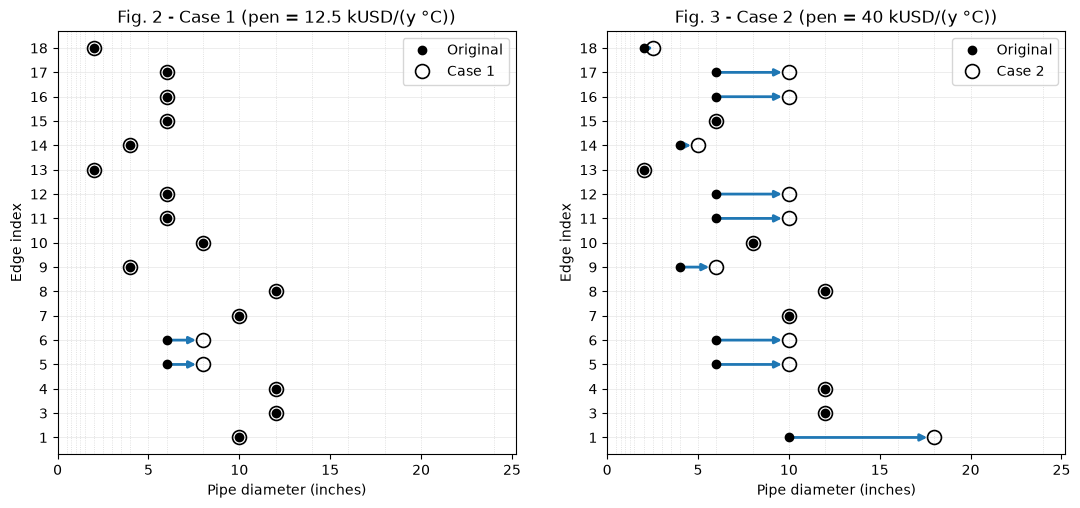

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
F.plot_diameter_dotchart(case, cases["case1"], ax=axes[0], label="Case 1", title="Fig. 2 - Case 1 (pen = 12.5 kUSD/(y °C))")
F.plot_diameter_dotchart(case, cases["case2"], ax=axes[1], label="Case 2", title="Fig. 3 - Case 2 (pen = 40 kUSD/(y °C))")
fig.savefig("../figures/fig02_03_diameters.png", dpi=150, bbox_inches="tight")
for name, s in cases.items():
    changed = {k: v for k, v in s.pipe_diameters().items() if any(e["kind"] == "pipe" and str(e["id"]) == k and e["changed"] for e in s.edges)}
    print(f"{name}: pump {s.pump_options()} | {len(changed)} pipes changed: {changed}")

> **A modelling note.** The first Bonmin run of Case 2 during this port returned a design with
> *zero* penalties for 53.4 kUSD/y, far below the published 189.8 kUSD/y. It was not a better
> optimum: the regularized Merkel integrand $1/(H^{sat}_m - H_m + 1)$ changes sign where the
> operating line crosses the saturation curve, so the equation $I_M = I_P$ has a spurious root at
> $T_{base} = T_{wb}$ (water leaving the tower at the wet-bulb temperature with a *negative*
> driving force at the top of the packing). The model therefore enforces
> $H^{sat}_m - H_m \ge 100\ \mathrm{J/kg}$ at every quadrature point, a physical requirement that
> the published solutions satisfy by a wide margin (> 40 kJ/kg). See `docs/model.md`.

## Fig. 4 - impact of the penalty factor (unlimited budget)

The sweep solves the unlimited-budget MINLP for penalty factors from 0 to 5 x 12.5 kUSD/(y °C).
Interventions evolve in steps because of their discrete nature.

,penalty factor (kUSD/(y C)),pipe (kUSD/y),pump (kUSD/y),penalty (kUSD/y),objective (kUSD/y),pump option,pipes changed,status
0,0.00,0.01,0.00,0.00,9.02,1,2,optimal
1,1.25,0.06,0.00,6.77,27.01,1,1,optimal
2,2.50,0.06,0.00,13.48,33.76,1,1,optimal
3,3.75,0.06,0.00,20.19,40.50,1,1,optimal
4,5.00,0.06,0.00,26.91,47.23,1,1,optimal
5,6.25,0.06,0.00,33.63,53.95,1,1,optimal
6,7.50,0.06,0.00,40.36,60.68,1,1,optimal
7,8.75,0.06,0.00,47.08,67.41,1,1,optimal
8,10.00,1.56,0.00,52.32,74.09,1,3,optimal
9,11.25,2.58,3.42,46.39,79.44,4,2,optimal


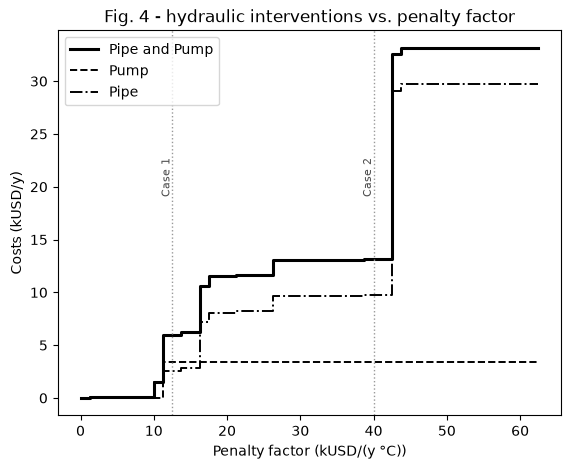

In [5]:
sweep = pipeline.run_penalty_sweep()
fig, ax = plt.subplots(figsize=(6.5, 5))
F.plot_penalty_sweep(sweep, ax=ax, markers={"Case 1": case.scenarios.penalty_cases["case1"], "Case 2": case.scenarios.penalty_cases["case2"]}, title="Fig. 4 - hydraulic interventions vs. penalty factor")
fig.savefig("../figures/fig04_penalty_sweep.png", dpi=150, bbox_inches="tight")
pd.DataFrame(
    {
        "penalty factor (kUSD/(y C))": [s.penalty_factor / 1e3 for s in sweep],
        "pipe (kUSD/y)": [s.costs["cpipe"] / 1e3 for s in sweep],
        "pump (kUSD/y)": [s.costs["cpump"] / 1e3 for s in sweep],
        "penalty (kUSD/y)": [s.costs["cpen"] / 1e3 for s in sweep],
        "objective (kUSD/y)": [s.costs["total_cost"] / 1e3 for s in sweep],
        "pump option": ["/".join(s.pump_options().values()) for s in sweep],
        "pipes changed": [sum(1 for e in s.edges if e["kind"] == "pipe" and e.get("changed")) for s in sweep],
        "status": [s.report["termination"] for s in sweep],
    }
).round(2)